In [1]:
import sys
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
import xgboost

print("Python:", sys.executable)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)

print("\nENVIRONMENT READY!")

Matplotlib is building the font cache; this may take a moment.


Python: /home/vidyasriganesh/ML_Mini_Project/Foreign_Currency_Forecast/venv/bin/python
NumPy: 2.5.3
Pandas: 3.0.6
Scikit-learn: 1.9.1
XGBoost: 3.4.1

ENVIRONMENT READY!


# Foreign Currency Exchange Rate Forecast

## Mini Project – Machine Learning

### Reference Paper
**Foreign Currency Exchange Rate Forecast**  
Jiahao Zhang, Jialu Sun, Jiequan Zhang  
Stanford CS229, 2019

---

## 1. Problem Statement

Foreign exchange rates are highly volatile and difficult to forecast because
they are influenced by economic conditions, financial markets and historical
price movements.

The objective of this project is to investigate whether machine learning
models can predict the future movement of major foreign exchange rates.

We focus on three currency pairs:

- GBP/USD
- USD/EUR
- USD/JPY

The project contains two prediction tasks:

1. **Sign Prediction (Classification)**  
   Predict whether the next-period exchange-rate return will be positive
   or negative.

2. **Log-Return Prediction (Regression)**  
   Predict the numerical value of the future exchange-rate log return.

The predicted returns can additionally be used to evaluate a simple
trading strategy.

---

## 2. Reference Methodology

The reference work evaluates several machine learning techniques:

- Logistic Regression
- Random Forest
- Support Vector Machine (SVM)
- Multi-Layer Perceptron (MLP)
- Lasso Regression
- Ridge Regression

The reference uses historical exchange-rate information together with
engineered financial features and macroeconomic variables.

The original study uses a chronological:

**80% Training / 10% Validation / 10% Testing**

split.

---

## 3. Project Extension

As an extension to the reference work, this project introduces:

**XGBoost**

XGBoost is a gradient-boosted decision-tree ensemble model. It is added
to investigate whether a modern boosting-based approach can improve
forecasting performance compared with the models used in the reference.

The additional model is evaluated using the same data split and evaluation
metrics to maintain a fair comparison.

---

## 4. Public Dataset Adaptation

The original study uses Bloomberg Terminal data, which is not freely
available to us.

Therefore, this reproduction uses publicly available historical foreign
exchange data from the Federal Reserve Bank of St. Louis (FRED) as a
closest publicly accessible alternative.

The difference between the original Bloomberg dataset and the public
FRED dataset will be considered when interpreting differences between
the reported and reproduced results.

In [2]:
# ============================================
# STEP 1: LOAD FOREIGN EXCHANGE DATA
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# FRED public data URLs
GBP_URL = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=DEXUSUK"
EUR_URL = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=DEXUSEU"
JPY_URL = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=DEXJPUS"

# Load datasets
gbp = pd.read_csv(GBP_URL)
eur = pd.read_csv(EUR_URL)
jpy = pd.read_csv(JPY_URL)

# Display basic information
print("GBP/USD dataset:")
print(gbp.head())

print("\nUSD/EUR dataset:")
print(eur.head())

print("\nUSD/JPY dataset:")
print(jpy.head())

GBP/USD dataset:
  observation_date  DEXUSUK
0       1971-01-04   2.3938
1       1971-01-05   2.3949
2       1971-01-06   2.3967
3       1971-01-07   2.3963
4       1971-01-08   2.3972

USD/EUR dataset:
  observation_date  DEXUSEU
0       1999-01-04   1.1812
1       1999-01-05   1.1760
2       1999-01-06   1.1636
3       1999-01-07   1.1672
4       1999-01-08   1.1554

USD/JPY dataset:
  observation_date  DEXJPUS
0       1971-01-04   357.73
1       1971-01-05   357.81
2       1971-01-06   357.86
3       1971-01-07   357.87
4       1971-01-08   357.82


In [3]:
# ============================================
# STEP 2: CLEAN AND ALIGN FX DATA
# Reference period: January 2001 - December 2018
# ============================================

# Rename columns to meaningful names
gbp = gbp.rename(columns={
    "observation_date": "Date",
    "DEXUSUK": "GBP_USD"
})

eur = eur.rename(columns={
    "observation_date": "Date",
    "DEXUSEU": "USD_EUR"
})

jpy = jpy.rename(columns={
    "observation_date": "Date",
    "DEXJPUS": "USD_JPY"
})

# Convert Date columns to datetime
gbp["Date"] = pd.to_datetime(gbp["Date"])
eur["Date"] = pd.to_datetime(eur["Date"])
jpy["Date"] = pd.to_datetime(jpy["Date"])

# Convert exchange-rate columns to numeric
gbp["GBP_USD"] = pd.to_numeric(gbp["GBP_USD"], errors="coerce")
eur["USD_EUR"] = pd.to_numeric(eur["USD_EUR"], errors="coerce")
jpy["USD_JPY"] = pd.to_numeric(jpy["USD_JPY"], errors="coerce")

# Keep the same period as the reference paper
START_DATE = "2001-01-01"
END_DATE = "2018-12-31"

gbp = gbp[(gbp["Date"] >= START_DATE) & (gbp["Date"] <= END_DATE)]
eur = eur[(eur["Date"] >= START_DATE) & (eur["Date"] <= END_DATE)]
jpy = jpy[(jpy["Date"] >= START_DATE) & (jpy["Date"] <= END_DATE)]

# Sort chronologically
gbp = gbp.sort_values("Date").reset_index(drop=True)
eur = eur.sort_values("Date").reset_index(drop=True)
jpy = jpy.sort_values("Date").reset_index(drop=True)

# Display information
print("GBP/USD:")
print(gbp.info())

print("\nUSD/EUR:")
print(eur.info())

print("\nUSD/JPY:")
print(jpy.info())

GBP/USD:
<class 'pandas.DataFrame'>
RangeIndex: 4696 entries, 0 to 4695
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   Date     4696 non-null   datetime64[us]
 1   GBP_USD  4518 non-null   float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 73.5 KB
None

USD/EUR:
<class 'pandas.DataFrame'>
RangeIndex: 4696 entries, 0 to 4695
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   Date     4696 non-null   datetime64[us]
 1   USD_EUR  4518 non-null   float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 73.5 KB
None

USD/JPY:
<class 'pandas.DataFrame'>
RangeIndex: 4696 entries, 0 to 4695
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   Date     4696 non-null   datetime64[us]
 1   USD_JPY  4518 non-null   float64       
dtypes: datetime

In [4]:
# ============================================
# STEP 3: DATA QUALITY CHECK
# ============================================

print("=" * 60)
print("DATASET QUALITY CHECK")
print("=" * 60)

for name, df, column in [
    ("GBP/USD", gbp, "GBP_USD"),
    ("USD/EUR", eur, "USD_EUR"),
    ("USD/JPY", jpy, "USD_JPY")
]:
    
    print(f"\n{name}")
    print("-" * 40)
    
    print("Number of rows:", len(df))
    print("Start date:", df["Date"].min().date())
    print("End date:", df["Date"].max().date())
    print("Missing values:", df[column].isna().sum())
    print("Duplicate dates:", df["Date"].duplicated().sum())
    print("Minimum rate:", df[column].min())
    print("Maximum rate:", df[column].max())

DATASET QUALITY CHECK

GBP/USD
----------------------------------------
Number of rows: 4696
Start date: 2001-01-01
End date: 2018-12-31
Missing values: 178
Duplicate dates: 0
Minimum rate: 1.2118
Maximum rate: 2.1104

USD/EUR
----------------------------------------
Number of rows: 4696
Start date: 2001-01-01
End date: 2018-12-31
Missing values: 178
Duplicate dates: 0
Minimum rate: 0.837
Maximum rate: 1.601

USD/JPY
----------------------------------------
Number of rows: 4696
Start date: 2001-01-01
End date: 2018-12-31
Missing values: 178
Duplicate dates: 0
Minimum rate: 75.72
Maximum rate: 134.77


In [5]:
# ============================================
# STEP 4: HANDLE MISSING VALUES
# ============================================

print("Missing values BEFORE filling:")
print("GBP/USD:", gbp["GBP_USD"].isna().sum())
print("USD/EUR:", eur["USD_EUR"].isna().sum())
print("USD/JPY:", jpy["USD_JPY"].isna().sum())

# Forward-fill missing observations
gbp["GBP_USD"] = gbp["GBP_USD"].ffill()
eur["USD_EUR"] = eur["USD_EUR"].ffill()
jpy["USD_JPY"] = jpy["USD_JPY"].ffill()

print("\nMissing values AFTER filling:")
print("GBP/USD:", gbp["GBP_USD"].isna().sum())
print("USD/EUR:", eur["USD_EUR"].isna().sum())
print("USD/JPY:", jpy["USD_JPY"].isna().sum())

Missing values BEFORE filling:
GBP/USD: 178
USD/EUR: 178
USD/JPY: 178

Missing values AFTER filling:
GBP/USD: 1
USD/EUR: 1
USD/JPY: 1


In [6]:
# ============================================
# STEP 5: COMBINE THE CURRENCY DATASETS
# ============================================

fx_data = gbp.merge(
    eur,
    on="Date",
    how="inner"
).merge(
    jpy,
    on="Date",
    how="inner"
)

fx_data = fx_data.sort_values("Date").reset_index(drop=True)

print("Combined dataset shape:", fx_data.shape)

print("\nFirst 5 observations:")
display(fx_data.head())

print("\nLast 5 observations:")
display(fx_data.tail())

print("\nMissing values:")
print(fx_data.isna().sum())

print("\nDuplicate dates:")
print(fx_data["Date"].duplicated().sum())

Combined dataset shape: (4696, 4)

First 5 observations:


,Date,GBP_USD,USD_EUR,USD_JPY
0,2001-01-01,NaN,NaN,NaN
1,2001-01-02,1.4977,0.9465,114.73
2,2001-01-03,1.5045,0.9473,114.26
3,2001-01-04,1.4930,0.9448,115.47
4,2001-01-05,1.4990,0.9535,116.19



Last 5 observations:


,Date,GBP_USD,USD_EUR,USD_JPY
4691,2018-12-25,1.2681,1.1402,111.14
4692,2018-12-26,1.2676,1.1408,110.45
4693,2018-12-27,1.2627,1.1412,110.78
4694,2018-12-28,1.2699,1.1445,110.34
4695,2018-12-31,1.2763,1.1456,109.70



Missing values:
Date       0
GBP_USD    1
USD_EUR    1
USD_JPY    1
dtype: int64

Duplicate dates:
0


In [7]:
# ============================================
# STEP 6: REMOVE REMAINING MISSING VALUES
# ============================================

print("Missing values BEFORE final cleanup:")
print(fx_data.isna().sum())

# Remove rows where any exchange rate is still missing
fx_data = fx_data.dropna().reset_index(drop=True)

print("\nMissing values AFTER final cleanup:")
print(fx_data.isna().sum())

print("\nFinal dataset shape:", fx_data.shape)

print("\nFirst 5 observations:")
display(fx_data.head())

print("\nLast 5 observations:")
display(fx_data.tail())

print("\nDuplicate dates:", fx_data["Date"].duplicated().sum())

Missing values BEFORE final cleanup:
Date       0
GBP_USD    1
USD_EUR    1
USD_JPY    1
dtype: int64

Missing values AFTER final cleanup:
Date       0
GBP_USD    0
USD_EUR    0
USD_JPY    0
dtype: int64

Final dataset shape: (4695, 4)

First 5 observations:


,Date,GBP_USD,USD_EUR,USD_JPY
0,2001-01-02,1.4977,0.9465,114.73
1,2001-01-03,1.5045,0.9473,114.26
2,2001-01-04,1.4930,0.9448,115.47
3,2001-01-05,1.4990,0.9535,116.19
4,2001-01-08,1.4969,0.9486,115.97



Last 5 observations:


,Date,GBP_USD,USD_EUR,USD_JPY
4690,2018-12-25,1.2681,1.1402,111.14
4691,2018-12-26,1.2676,1.1408,110.45
4692,2018-12-27,1.2627,1.1412,110.78
4693,2018-12-28,1.2699,1.1445,110.34
4694,2018-12-31,1.2763,1.1456,109.70



Duplicate dates: 0


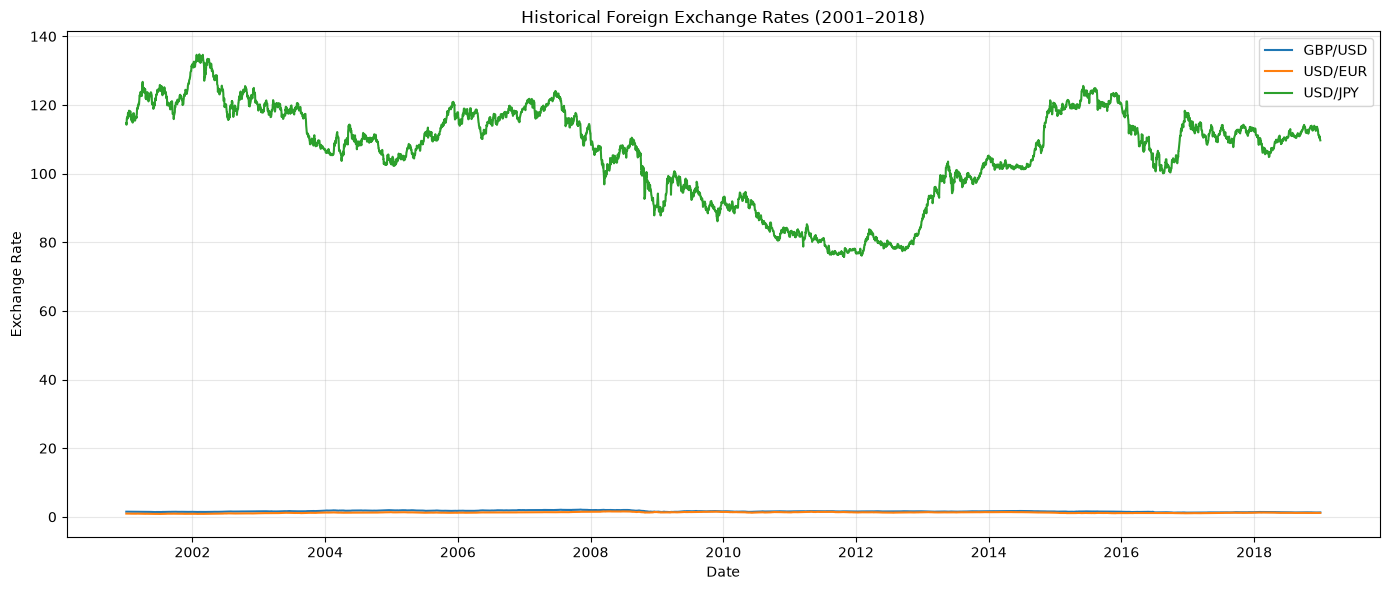

In [8]:
# ============================================
# STEP 7: EXPLORATORY DATA ANALYSIS
# Exchange Rate Trends
# ============================================

plt.figure(figsize=(14, 6))

plt.plot(fx_data["Date"], fx_data["GBP_USD"], label="GBP/USD")
plt.plot(fx_data["Date"], fx_data["USD_EUR"], label="USD/EUR")
plt.plot(fx_data["Date"], fx_data["USD_JPY"], label="USD/JPY")

plt.title("Historical Foreign Exchange Rates (2001–2018)")
plt.xlabel("Date")
plt.ylabel("Exchange Rate")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

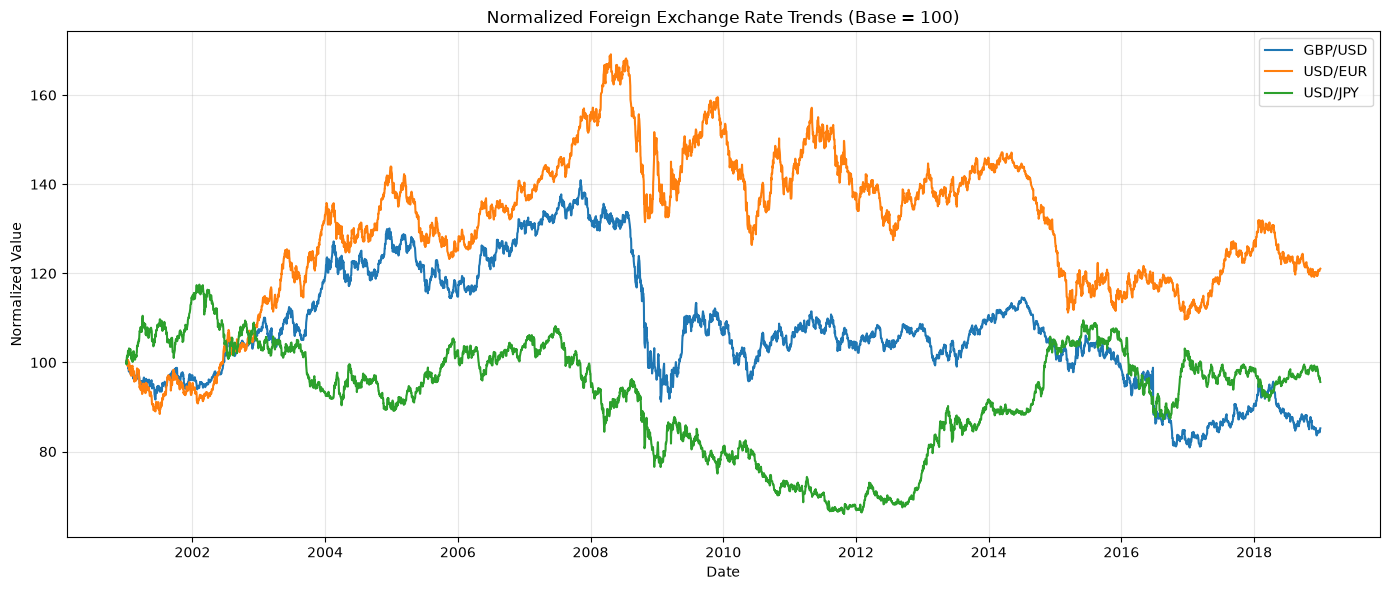

In [9]:
# ============================================
# STEP 8: NORMALIZED EXCHANGE RATE COMPARISON
# ============================================

# Normalize each currency to start at 100
normalized_fx = fx_data.copy()

for column in ["GBP_USD", "USD_EUR", "USD_JPY"]:
    normalized_fx[column] = (
        normalized_fx[column] / normalized_fx[column].iloc[0]
    ) * 100

# Plot normalized values
plt.figure(figsize=(14, 6))

plt.plot(
    normalized_fx["Date"],
    normalized_fx["GBP_USD"],
    label="GBP/USD"
)

plt.plot(
    normalized_fx["Date"],
    normalized_fx["USD_EUR"],
    label="USD/EUR"
)

plt.plot(
    normalized_fx["Date"],
    normalized_fx["USD_JPY"],
    label="USD/JPY"
)

plt.title("Normalized Foreign Exchange Rate Trends (Base = 100)")
plt.xlabel("Date")
plt.ylabel("Normalized Value")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [10]:
# ============================================
# STEP 9: CALCULATE DAILY LOG RETURNS
# ============================================

# Create a copy so the original exchange-rate data remains unchanged
returns_data = fx_data.copy()

# Calculate daily log returns
for column in ["GBP_USD", "USD_EUR", "USD_JPY"]:
    returns_data[f"{column}_Return"] = np.log(
        returns_data[column] / returns_data[column].shift(1)
    )

# Remove the first row because it has no previous-day value
returns_data = returns_data.dropna().reset_index(drop=True)

print("Returns dataset shape:", returns_data.shape)

print("\nFirst 5 observations:")
display(
    returns_data[
        [
            "Date",
            "GBP_USD_Return",
            "USD_EUR_Return",
            "USD_JPY_Return"
        ]
    ].head()
)

print("\nSummary statistics:")
display(
    returns_data[
        [
            "GBP_USD_Return",
            "USD_EUR_Return",
            "USD_JPY_Return"
        ]
    ].describe()
)

Returns dataset shape: (4694, 7)

First 5 observations:


,Date,GBP_USD_Return,USD_EUR_Return,USD_JPY_Return
0,2001-01-03,0.004530,0.000845,-0.004105
1,2001-01-04,-0.007673,-0.002643,0.010534
2,2001-01-05,0.004011,0.009166,0.006216
3,2001-01-08,-0.001402,-0.005152,-0.001895
4,2001-01-09,-0.004620,-0.009427,0.005761



Summary statistics:


,GBP_USD_Return,USD_EUR_Return,USD_JPY_Return
count,4694.000000,4694.000000,4694.000000
mean,-0.000034,0.000041,-0.000010
std,0.005905,0.006009,0.006249
min,-0.081694,-0.030031,-0.052156
25%,-0.003039,-0.003147,-0.003259
50%,0.000000,0.000000,0.000000
75%,0.003182,0.003359,0.003370
max,0.044349,0.046208,0.033428


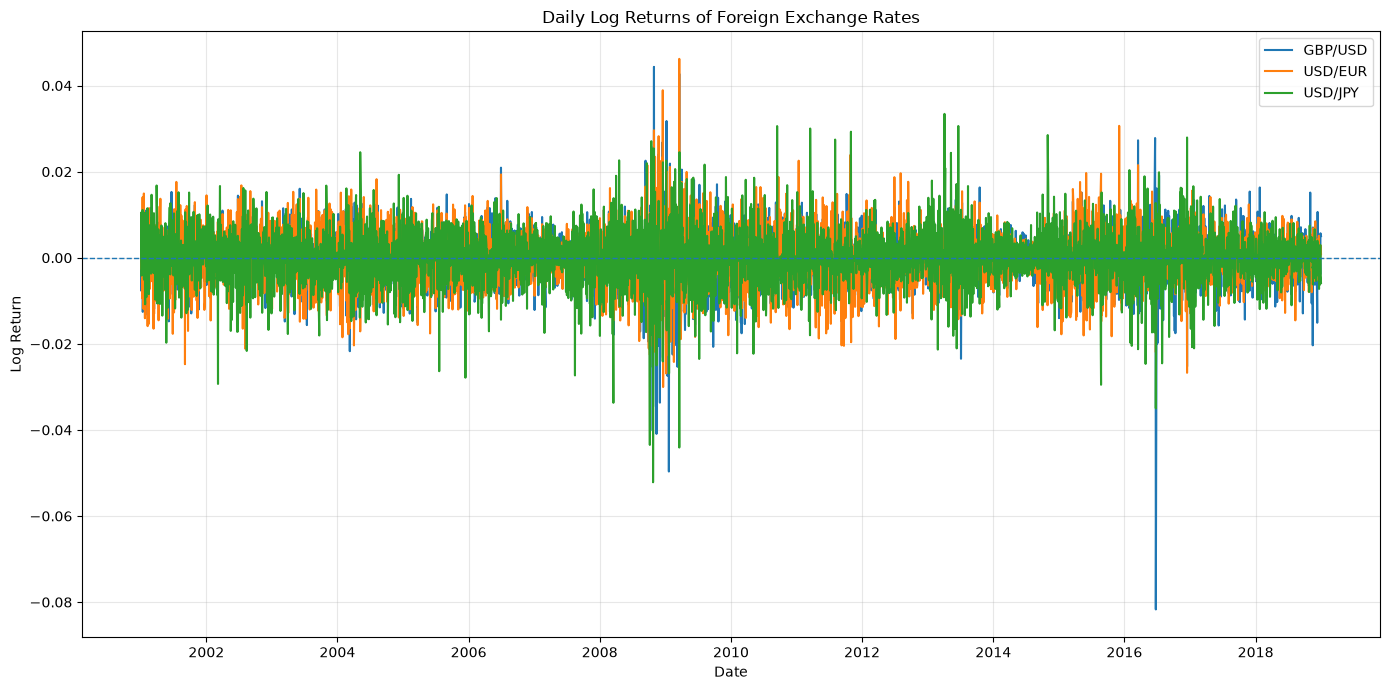

In [11]:
# ============================================
# STEP 10: VISUALIZE DAILY LOG RETURNS
# ============================================

plt.figure(figsize=(14, 7))

plt.plot(
    returns_data["Date"],
    returns_data["GBP_USD_Return"],
    label="GBP/USD"
)

plt.plot(
    returns_data["Date"],
    returns_data["USD_EUR_Return"],
    label="USD/EUR"
)

plt.plot(
    returns_data["Date"],
    returns_data["USD_JPY_Return"],
    label="USD/JPY"
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

plt.title("Daily Log Returns of Foreign Exchange Rates")
plt.xlabel("Date")
plt.ylabel("Log Return")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Correlation Matrix:


,GBP_USD_Return,USD_EUR_Return,USD_JPY_Return
GBP_USD_Return,1.000000,0.646054,-0.134159
USD_EUR_Return,0.646054,1.000000,-0.305487
USD_JPY_Return,-0.134159,-0.305487,1.000000


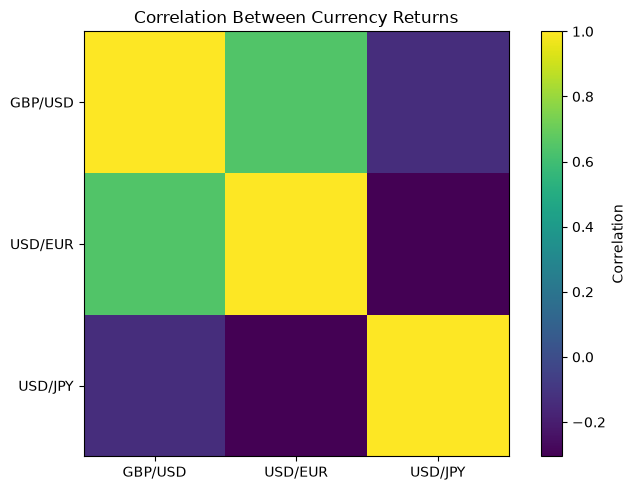

In [12]:
# ============================================
# STEP 11: CORRELATION ANALYSIS
# ============================================

# Select only the return columns
return_columns = [
    "GBP_USD_Return",
    "USD_EUR_Return",
    "USD_JPY_Return"
]

correlation_matrix = returns_data[return_columns].corr()

print("Correlation Matrix:")
display(correlation_matrix)

# Visualize the correlation matrix
plt.figure(figsize=(7, 5))

plt.imshow(
    correlation_matrix,
    interpolation="nearest"
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(return_columns)),
    ["GBP/USD", "USD/EUR", "USD/JPY"]
)

plt.yticks(
    range(len(return_columns)),
    ["GBP/USD", "USD/EUR", "USD/JPY"]
)

plt.title("Correlation Between Currency Returns")

plt.tight_layout()
plt.show()

In [13]:
# ============================================
# STEP 12A: CREATE LAG FEATURES
# ============================================

# Work on a copy
features_data = returns_data.copy()

# Currency return columns
currency_returns = [
    "GBP_USD_Return",
    "USD_EUR_Return",
    "USD_JPY_Return"
]

# Create lag features for the previous 1, 2, 3 and 5 trading days
for column in currency_returns:
    for lag in [1, 2, 3, 5]:
        features_data[f"{column}_Lag{lag}"] = (
            features_data[column].shift(lag)
        )

print("Dataset shape after creating lag features:")
print(features_data.shape)

print("\nFeature columns:")
print(features_data.columns.tolist())

Dataset shape after creating lag features:
(4694, 19)

Feature columns:
['Date', 'GBP_USD', 'USD_EUR', 'USD_JPY', 'GBP_USD_Return', 'USD_EUR_Return', 'USD_JPY_Return', 'GBP_USD_Return_Lag1', 'GBP_USD_Return_Lag2', 'GBP_USD_Return_Lag3', 'GBP_USD_Return_Lag5', 'USD_EUR_Return_Lag1', 'USD_EUR_Return_Lag2', 'USD_EUR_Return_Lag3', 'USD_EUR_Return_Lag5', 'USD_JPY_Return_Lag1', 'USD_JPY_Return_Lag2', 'USD_JPY_Return_Lag3', 'USD_JPY_Return_Lag5']


In [14]:
# ============================================
# STEP 12B: MOVING AVERAGES AND VOLATILITY
# ============================================

# Create rolling features using only past information
for column in currency_returns:
    
    # 5-day moving average
    features_data[f"{column}_MA5"] = (
        features_data[column]
        .shift(1)
        .rolling(window=5)
        .mean()
    )
    
    # 10-day moving average
    features_data[f"{column}_MA10"] = (
        features_data[column]
        .shift(1)
        .rolling(window=10)
        .mean()
    )
    
    # 20-day moving average
    features_data[f"{column}_MA20"] = (
        features_data[column]
        .shift(1)
        .rolling(window=20)
        .mean()
    )
    
    # 20-day rolling volatility
    features_data[f"{column}_Vol20"] = (
        features_data[column]
        .shift(1)
        .rolling(window=20)
        .std()
    )

print("Dataset shape after moving averages and volatility:")
print(features_data.shape)

print("\nNew feature columns:")
print([
    column for column in features_data.columns
    if "MA" in column or "Vol" in column
])

Dataset shape after moving averages and volatility:
(4694, 31)

New feature columns:
['GBP_USD_Return_MA5', 'GBP_USD_Return_MA10', 'GBP_USD_Return_MA20', 'GBP_USD_Return_Vol20', 'USD_EUR_Return_MA5', 'USD_EUR_Return_MA10', 'USD_EUR_Return_MA20', 'USD_EUR_Return_Vol20', 'USD_JPY_Return_MA5', 'USD_JPY_Return_MA10', 'USD_JPY_Return_MA20', 'USD_JPY_Return_Vol20']


In [15]:
# ============================================
# STEP 12C: MOMENTUM FEATURES
# ============================================

for column in currency_returns:

    # Previous 5-day cumulative return
    features_data[f"{column}_Momentum5"] = (
        features_data[column]
        .shift(1)
        .rolling(window=5)
        .sum()
    )

    # Previous 10-day cumulative return
    features_data[f"{column}_Momentum10"] = (
        features_data[column]
        .shift(1)
        .rolling(window=10)
        .sum()
    )

print("Dataset shape after momentum features:")
print(features_data.shape)

print("\nMomentum features:")
print([
    column for column in features_data.columns
    if "Momentum" in column
])

Dataset shape after momentum features:
(4694, 37)

Momentum features:
['GBP_USD_Return_Momentum5', 'GBP_USD_Return_Momentum10', 'USD_EUR_Return_Momentum5', 'USD_EUR_Return_Momentum10', 'USD_JPY_Return_Momentum5', 'USD_JPY_Return_Momentum10']


In [16]:
# ============================================
# STEP 13: CREATE NEXT-DAY TARGETS
# ============================================

# Target currency
TARGET_CURRENCY = "GBP_USD_Return"

# --------------------------------------------
# Regression target
# --------------------------------------------
# Tomorrow's return
features_data["Target_Return"] = (
    features_data[TARGET_CURRENCY].shift(-1)
)

# --------------------------------------------
# Classification target
# --------------------------------------------
# 1 = next-day return is positive
# 0 = next-day return is zero or negative
features_data["Target_Direction"] = (
    features_data["Target_Return"] > 0
).astype(int)

print("Target columns created.")

print("\nTarget preview:")
display(
    features_data[
        [
            "Date",
            TARGET_CURRENCY,
            "Target_Return",
            "Target_Direction"
        ]
    ].head(10)
)

print("\nTarget direction distribution:")
print(
    features_data["Target_Direction"].value_counts()
)

print("\nTarget return statistics:")
print(
    features_data["Target_Return"].describe()
)

Target columns created.

Target preview:


,Date,GBP_USD_Return,Target_Return,Target_Direction
0,2001-01-03,0.004530,-0.007673,0
1,2001-01-04,-0.007673,0.004011,1
2,2001-01-05,0.004011,-0.001402,0
3,2001-01-08,-0.001402,-0.004620,0
4,2001-01-09,-0.004620,0.000671,1
5,2001-01-10,0.000671,0.003682,1
6,2001-01-11,0.003682,-0.012575,0
7,2001-01-12,-0.012575,0.000000,0
8,2001-01-15,0.000000,-0.006994,0
9,2001-01-16,-0.006994,0.003266,1



Target direction distribution:
Target_Direction
0    2413
1    2281
Name: count, dtype: int64

Target return statistics:
count    4693.000000
mean       -0.000035
std         0.005905
min        -0.081694
25%        -0.003039
50%         0.000000
75%         0.003178
max         0.044349
Name: Target_Return, dtype: float64


In [17]:
# ============================================
# STEP 13B: REMOVE ROWS WITHOUT A FUTURE TARGET
# ============================================

print("Rows before removing missing targets:", len(features_data))

# Remove the final row because there is no next-day return available
features_data = features_data.dropna(
    subset=["Target_Return"]
).reset_index(drop=True)

# Recreate direction after removing missing targets
features_data["Target_Direction"] = (
    features_data["Target_Return"] > 0
).astype(int)

print("Rows after removing missing targets:", len(features_data))

print("\nMissing target values:")
print(features_data[["Target_Return", "Target_Direction"]].isna().sum())

print("\nTarget direction distribution:")
print(features_data["Target_Direction"].value_counts())

print("\nFinal target preview:")
display(
    features_data[
        [
            "Date",
            "GBP_USD_Return",
            "Target_Return",
            "Target_Direction"
        ]
    ].tail()
)

Rows before removing missing targets: 4694
Rows after removing missing targets: 4693

Missing target values:
Target_Return       0
Target_Direction    0
dtype: int64

Target direction distribution:
Target_Direction
0    2412
1    2281
Name: count, dtype: int64

Final target preview:


,Date,GBP_USD_Return,Target_Return,Target_Direction
4688,2018-12-24,0.000000,0.000000,0
4689,2018-12-25,0.000000,-0.000394,0
4690,2018-12-26,-0.000394,-0.003873,0
4691,2018-12-27,-0.003873,0.005686,1
4692,2018-12-28,0.005686,0.005027,1


In [18]:
# ============================================
# STEP 14: FINAL FEATURE CLEANUP
# ============================================

print("Dataset shape BEFORE removing feature NaNs:")
print(features_data.shape)

print("\nMissing values per column:")

missing_features = features_data.isna().sum()

display(
    missing_features[missing_features > 0]
)

# Remove rows with missing engineered features
features_data = features_data.dropna().reset_index(drop=True)

print("\nDataset shape AFTER removing feature NaNs:")
print(features_data.shape)

print("\nTotal missing values after cleanup:")
print(features_data.isna().sum().sum())

print("\nDate range:")
print("Start:", features_data["Date"].min().date())
print("End:", features_data["Date"].max().date())

Dataset shape BEFORE removing feature NaNs:
(4693, 39)

Missing values per column:


GBP_USD_Return_Lag1           1
GBP_USD_Return_Lag2           2
GBP_USD_Return_Lag3           3
GBP_USD_Return_Lag5           5
USD_EUR_Return_Lag1           1
USD_EUR_Return_Lag2           2
USD_EUR_Return_Lag3           3
USD_EUR_Return_Lag5           5
USD_JPY_Return_Lag1           1
USD_JPY_Return_Lag2           2
USD_JPY_Return_Lag3           3
USD_JPY_Return_Lag5           5
GBP_USD_Return_MA5            5
GBP_USD_Return_MA10          10
GBP_USD_Return_MA20          20
GBP_USD_Return_Vol20         20
USD_EUR_Return_MA5            5
USD_EUR_Return_MA10          10
USD_EUR_Return_MA20          20
USD_EUR_Return_Vol20         20
USD_JPY_Return_MA5            5
USD_JPY_Return_MA10          10
USD_JPY_Return_MA20          20
USD_JPY_Return_Vol20         20
GBP_USD_Return_Momentum5      5
GBP_USD_Return_Momentum10    10
USD_EUR_Return_Momentum5      5
USD_EUR_Return_Momentum10    10
USD_JPY_Return_Momentum5      5
USD_JPY_Return_Momentum10    10
dtype: int64


Dataset shape AFTER removing feature NaNs:
(4673, 39)

Total missing values after cleanup:
0

Date range:
Start: 2001-01-31
End: 2018-12-28


In [19]:
# ============================================
# STEP 15A: CHRONOLOGICAL TRAIN/VAL/TEST SPLIT
# ============================================

# Features
# Remove Date and both target columns.
# Everything else is available information for prediction.
feature_columns = [
    column
    for column in features_data.columns
    if column not in [
        "Date",
        "Target_Return",
        "Target_Direction"
    ]
]

X = features_data[feature_columns].copy()

# Classification target
y_classification = features_data["Target_Direction"].copy()

# Regression target
y_regression = features_data["Target_Return"].copy()

print("Number of features:", len(feature_columns))
print("Feature matrix shape:", X.shape)

# --------------------------------------------
# Chronological 80 / 10 / 10 split
# --------------------------------------------

n = len(features_data)

train_end = int(n * 0.80)
validation_end = int(n * 0.90)

X_train = X.iloc[:train_end].copy()
X_val = X.iloc[train_end:validation_end].copy()
X_test = X.iloc[validation_end:].copy()

y_class_train = y_classification.iloc[:train_end].copy()
y_class_val = y_classification.iloc[train_end:validation_end].copy()
y_class_test = y_classification.iloc[validation_end:].copy()

y_reg_train = y_regression.iloc[:train_end].copy()
y_reg_val = y_regression.iloc[train_end:validation_end].copy()
y_reg_test = y_regression.iloc[validation_end:].copy()

# --------------------------------------------
# Display split information
# --------------------------------------------

print("\nDATA SPLIT")
print("=" * 50)

print("\nTraining:")
print("Rows:", len(X_train))
print("Start:", features_data["Date"].iloc[0].date())
print("End:", features_data["Date"].iloc[train_end - 1].date())

print("\nValidation:")
print("Rows:", len(X_val))
print("Start:", features_data["Date"].iloc[train_end].date())
print("End:", features_data["Date"].iloc[validation_end - 1].date())

print("\nTesting:")
print("Rows:", len(X_test))
print("Start:", features_data["Date"].iloc[validation_end].date())
print("End:", features_data["Date"].iloc[-1].date())

Number of features: 36
Feature matrix shape: (4673, 36)

DATA SPLIT

Training:
Rows: 3738
Start: 2001-01-31
End: 2015-05-29

Validation:
Rows: 467
Start: 2015-06-01
End: 2017-03-14

Testing:
Rows: 468
Start: 2017-03-15
End: 2018-12-28


In [20]:
# ============================================
# STEP 15B: FEATURE SCALING
# ============================================

from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

# Fit ONLY on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform validation and test using the same scaler
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Original feature shape:")
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("\nScaled feature shape:")
print("X_train_scaled:", X_train_scaled.shape)
print("X_val_scaled:", X_val_scaled.shape)
print("X_test_scaled:", X_test_scaled.shape)

print("\nTraining scaled feature statistics:")

print(
    "Mean of first feature:",
    X_train_scaled[:, 0].mean()
)

print(
    "Std of first feature:",
    X_train_scaled[:, 0].std()
)

Original feature shape:
X_train: (3738, 36)
X_val: (467, 36)
X_test: (468, 36)

Scaled feature shape:
X_train_scaled: (3738, 36)
X_val_scaled: (467, 36)
X_test_scaled: (468, 36)

Training scaled feature statistics:
Mean of first feature: -9.124144279423437e-17
Std of first feature: 1.0


In [21]:
# ============================================
# STEP 16: LOGISTIC REGRESSION
# Classification Model
# ============================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Create Logistic Regression model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train ONLY on training data
logistic_model.fit(
    X_train_scaled,
    y_class_train
)

# Predict validation data
logistic_val_pred = logistic_model.predict(
    X_val_scaled
)

# Calculate validation metrics
logistic_accuracy = accuracy_score(
    y_class_val,
    logistic_val_pred
)

logistic_precision = precision_score(
    y_class_val,
    logistic_val_pred,
    zero_division=0
)

logistic_recall = recall_score(
    y_class_val,
    logistic_val_pred,
    zero_division=0
)

logistic_f1 = f1_score(
    y_class_val,
    logistic_val_pred,
    zero_division=0
)

logistic_cm = confusion_matrix(
    y_class_val,
    logistic_val_pred
)

print("LOGISTIC REGRESSION — VALIDATION RESULTS")
print("=" * 50)

print(f"Accuracy : {logistic_accuracy:.4f}")
print(f"Precision: {logistic_precision:.4f}")
print(f"Recall   : {logistic_recall:.4f}")
print(f"F1 Score : {logistic_f1:.4f}")

print("\nConfusion Matrix:")
print(logistic_cm)

print("\nClassification Report:")
print(
    classification_report(
        y_class_val,
        logistic_val_pred,
        target_names=["DOWN", "UP"],
        zero_division=0
    )
)

LOGISTIC REGRESSION — VALIDATION RESULTS
Accuracy : 0.4775
Precision: 0.4346
Recall   : 0.5381
F1 Score : 0.4809

Confusion Matrix:
[[110 147]
 [ 97 113]]

Classification Report:
              precision    recall  f1-score   support

        DOWN       0.53      0.43      0.47       257
          UP       0.43      0.54      0.48       210

    accuracy                           0.48       467
   macro avg       0.48      0.48      0.48       467
weighted avg       0.49      0.48      0.48       467



In [22]:
# ============================================
# STEP 17: RANDOM FOREST CLASSIFICATION
# ============================================

from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_classifier = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# Train on training data
# Random Forest does not require scaling
rf_classifier.fit(
    X_train,
    y_class_train
)

# Predict validation data
rf_val_pred = rf_classifier.predict(X_val)

# Calculate metrics
rf_accuracy = accuracy_score(
    y_class_val,
    rf_val_pred
)

rf_precision = precision_score(
    y_class_val,
    rf_val_pred,
    zero_division=0
)

rf_recall = recall_score(
    y_class_val,
    rf_val_pred,
    zero_division=0
)

rf_f1 = f1_score(
    y_class_val,
    rf_val_pred,
    zero_division=0
)

rf_cm = confusion_matrix(
    y_class_val,
    rf_val_pred
)

print("RANDOM FOREST — VALIDATION RESULTS")
print("=" * 50)

print(f"Accuracy : {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall   : {rf_recall:.4f}")
print(f"F1 Score : {rf_f1:.4f}")

print("\nConfusion Matrix:")
print(rf_cm)

print("\nClassification Report:")
print(
    classification_report(
        y_class_val,
        rf_val_pred,
        target_names=["DOWN", "UP"],
        zero_division=0
    )
)

RANDOM FOREST — VALIDATION RESULTS
Accuracy : 0.5161
Precision: 0.4710
Recall   : 0.6190
F1 Score : 0.5350

Confusion Matrix:
[[111 146]
 [ 80 130]]

Classification Report:
              precision    recall  f1-score   support

        DOWN       0.58      0.43      0.50       257
          UP       0.47      0.62      0.53       210

    accuracy                           0.52       467
   macro avg       0.53      0.53      0.52       467
weighted avg       0.53      0.52      0.51       467



In [23]:
# ============================================
# STEP 18: SVM CLASSIFICATION
# ============================================

from sklearn.svm import SVC

# Create SVM with RBF kernel
svm_classifier = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    random_state=42
)

# Train on training data
svm_classifier.fit(
    X_train_scaled,
    y_class_train
)

# Predict validation data
svm_val_pred = svm_classifier.predict(
    X_val_scaled
)

# Calculate metrics
svm_accuracy = accuracy_score(
    y_class_val,
    svm_val_pred
)

svm_precision = precision_score(
    y_class_val,
    svm_val_pred,
    zero_division=0
)

svm_recall = recall_score(
    y_class_val,
    svm_val_pred,
    zero_division=0
)

svm_f1 = f1_score(
    y_class_val,
    svm_val_pred,
    zero_division=0
)

svm_cm = confusion_matrix(
    y_class_val,
    svm_val_pred
)

print("SVM — VALIDATION RESULTS")
print("=" * 50)

print(f"Accuracy : {svm_accuracy:.4f}")
print(f"Precision: {svm_precision:.4f}")
print(f"Recall   : {svm_recall:.4f}")
print(f"F1 Score : {svm_f1:.4f}")

print("\nConfusion Matrix:")
print(svm_cm)

print("\nClassification Report:")
print(
    classification_report(
        y_class_val,
        svm_val_pred,
        target_names=["DOWN", "UP"],
        zero_division=0
    )
)

SVM — VALIDATION RESULTS
Accuracy : 0.4968
Precision: 0.4552
Recall   : 0.6048
F1 Score : 0.5194

Confusion Matrix:
[[105 152]
 [ 83 127]]

Classification Report:
              precision    recall  f1-score   support

        DOWN       0.56      0.41      0.47       257
          UP       0.46      0.60      0.52       210

    accuracy                           0.50       467
   macro avg       0.51      0.51      0.50       467
weighted avg       0.51      0.50      0.49       467



In [24]:
# ============================================
# STEP 19: MLP CLASSIFICATION
# ============================================

from sklearn.neural_network import MLPClassifier

# Create MLP neural network
mlp_classifier = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    alpha=0.0001,
    learning_rate_init=0.001,
    max_iter=300,
    early_stopping=True,
    validation_fraction=0.1,
    random_state=42
)

# Train on scaled training data
mlp_classifier.fit(
    X_train_scaled,
    y_class_train
)

# Predict validation data
mlp_val_pred = mlp_classifier.predict(
    X_val_scaled
)

# Calculate metrics
mlp_accuracy = accuracy_score(
    y_class_val,
    mlp_val_pred
)

mlp_precision = precision_score(
    y_class_val,
    mlp_val_pred,
    zero_division=0
)

mlp_recall = recall_score(
    y_class_val,
    mlp_val_pred,
    zero_division=0
)

mlp_f1 = f1_score(
    y_class_val,
    mlp_val_pred,
    zero_division=0
)

mlp_cm = confusion_matrix(
    y_class_val,
    mlp_val_pred
)

print("MLP — VALIDATION RESULTS")
print("=" * 50)

print(f"Accuracy : {mlp_accuracy:.4f}")
print(f"Precision: {mlp_precision:.4f}")
print(f"Recall   : {mlp_recall:.4f}")
print(f"F1 Score : {mlp_f1:.4f}")

print("\nConfusion Matrix:")
print(mlp_cm)

print("\nClassification Report:")
print(
    classification_report(
        y_class_val,
        mlp_val_pred,
        target_names=["DOWN", "UP"],
        zero_division=0
    )
)

MLP — VALIDATION RESULTS
Accuracy : 0.5075
Precision: 0.4565
Recall   : 0.5000
F1 Score : 0.4773

Confusion Matrix:
[[132 125]
 [105 105]]

Classification Report:
              precision    recall  f1-score   support

        DOWN       0.56      0.51      0.53       257
          UP       0.46      0.50      0.48       210

    accuracy                           0.51       467
   macro avg       0.51      0.51      0.51       467
weighted avg       0.51      0.51      0.51       467



In [25]:
# ============================================
# STEP 20: CLASSIFICATION MODEL COMPARISON
# ============================================

classification_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "SVM",
        "MLP"
    ],
    "Accuracy": [
        logistic_accuracy,
        rf_accuracy,
        svm_accuracy,
        mlp_accuracy
    ],
    "Precision": [
        logistic_precision,
        rf_precision,
        svm_precision,
        mlp_precision
    ],
    "Recall": [
        logistic_recall,
        rf_recall,
        svm_recall,
        mlp_recall
    ],
    "F1 Score": [
        logistic_f1,
        rf_f1,
        svm_f1,
        mlp_f1
    ]
})

classification_results = classification_results.sort_values(
    "F1 Score",
    ascending=False
).reset_index(drop=True)

print("CLASSIFICATION MODEL COMPARISON — VALIDATION")
print("=" * 70)

display(
    classification_results.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}"
    })
)

CLASSIFICATION MODEL COMPARISON — VALIDATION


,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.5161,0.4710,0.6190,0.5350
1,SVM,0.4968,0.4552,0.6048,0.5194
2,Logistic Regression,0.4775,0.4346,0.5381,0.4809
3,MLP,0.5075,0.4565,0.5000,0.4773


In [26]:
# ============================================
# STEP 21: REGRESSION MODELS
# ============================================

from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import Lasso, Ridge
from xgboost import XGBRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------
# Helper function for regression evaluation
# ------------------------------------------------

def evaluate_regression_model(name, model, X_train_data, X_val_data):
    
    # Train
    model.fit(
        X_train_data,
        y_reg_train
    )
    
    # Predict validation set
    predictions = model.predict(
        X_val_data
    )
    
    # Metrics
    mae = mean_absolute_error(
        y_reg_val,
        predictions
    )
    
    mse = mean_squared_error(
        y_reg_val,
        predictions
    )
    
    rmse = np.sqrt(mse)
    
    r2 = r2_score(
        y_reg_val,
        predictions
    )
    
    print(f"\n{name}")
    print("-" * 50)
    print(f"MAE  : {mae:.8f}")
    print(f"MSE  : {mse:.8f}")
    print(f"RMSE : {rmse:.8f}")
    print(f"R²   : {r2:.4f}")
    
    return {
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    }


# ============================================
# 1. RANDOM FOREST REGRESSOR
# ============================================

rf_regressor = RandomForestRegressor(
    n_estimators=300,
    max_depth=8,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_reg_result = evaluate_regression_model(
    "Random Forest",
    rf_regressor,
    X_train,
    X_val
)


# ============================================
# 2. SVM REGRESSOR
# ============================================

svm_regressor = SVR(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    epsilon=0.0001
)

svm_reg_result = evaluate_regression_model(
    "SVM",
    svm_regressor,
    X_train_scaled,
    X_val_scaled
)


# ============================================
# 3. MLP REGRESSOR
# ============================================

mlp_regressor = MLPRegressor(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    alpha=0.0001,
    learning_rate_init=0.001,
    max_iter=300,
    early_stopping=True,
    validation_fraction=0.1,
    random_state=42
)

mlp_reg_result = evaluate_regression_model(
    "MLP",
    mlp_regressor,
    X_train_scaled,
    X_val_scaled
)


# ============================================
# 4. LASSO REGRESSION
# ============================================

lasso_regressor = Lasso(
    alpha=0.0001,
    max_iter=10000
)

lasso_reg_result = evaluate_regression_model(
    "Lasso",
    lasso_regressor,
    X_train_scaled,
    X_val_scaled
)


# ============================================
# 5. RIDGE REGRESSION
# ============================================

ridge_regressor = Ridge(
    alpha=1.0
)

ridge_reg_result = evaluate_regression_model(
    "Ridge",
    ridge_regressor,
    X_train_scaled,
    X_val_scaled
)


# ============================================
# 6. XGBOOST — PROJECT EXTENSION
# ============================================

xgb_regressor = XGBRegressor(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_reg_result = evaluate_regression_model(
    "XGBoost",
    xgb_regressor,
    X_train,
    X_val
)


# ============================================
# CREATE COMPARISON TABLE
# ============================================

regression_results = pd.DataFrame([
    rf_reg_result,
    svm_reg_result,
    mlp_reg_result,
    lasso_reg_result,
    ridge_reg_result,
    xgb_reg_result
])

# Lower RMSE is better
regression_results = regression_results.sort_values(
    "RMSE",
    ascending=True
).reset_index(drop=True)

print("\n\nREGRESSION MODEL COMPARISON — VALIDATION")
print("=" * 75)

display(
    regression_results.style.format({
        "MAE": "{:.8f}",
        "MSE": "{:.8f}",
        "RMSE": "{:.8f}",
        "R2": "{:.4f}"
    })
)


Random Forest
--------------------------------------------------
MAE  : 0.00545112
MSE  : 0.00006269
RMSE : 0.00791755
R²   : -0.1490

SVM
--------------------------------------------------
MAE  : 0.00690770
MSE  : 0.00008907
RMSE : 0.00943771
R²   : -0.6325


/home/vidyasriganesh/ML_Mini_Project/Foreign_Currency_Forecast/venv/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(



MLP
--------------------------------------------------
MAE  : 0.01359265
MSE  : 0.00045994
RMSE : 0.02144613
R²   : -7.4299

Lasso
--------------------------------------------------
MAE  : 0.00482885
MSE  : 0.00005488
RMSE : 0.00740834
R²   : -0.0059

Ridge
--------------------------------------------------
MAE  : 0.00494931
MSE  : 0.00005547
RMSE : 0.00744764
R²   : -0.0166

XGBoost
--------------------------------------------------
MAE  : 0.00536010
MSE  : 0.00006188
RMSE : 0.00786628
R²   : -0.1341


REGRESSION MODEL COMPARISON — VALIDATION


,Model,MAE,MSE,RMSE,R2
0,Lasso,0.00482885,0.00005488,0.00740834,-0.0059
1,Ridge,0.00494931,0.00005547,0.00744764,-0.0166
2,XGBoost,0.00536010,0.00006188,0.00786628,-0.1341
3,Random Forest,0.00545112,0.00006269,0.00791755,-0.1490
4,SVM,0.00690770,0.00008907,0.00943771,-0.6325
5,MLP,0.01359265,0.00045994,0.02144613,-7.4299


In [27]:
# ============================================
# STEP 22: FINAL TEST EVALUATION
# ============================================

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import Lasso

# ------------------------------------------------
# COMBINE TRAIN + VALIDATION
# ------------------------------------------------

X_train_full = pd.concat(
    [X_train, X_val],
    axis=0
)

y_class_train_full = pd.concat(
    [y_class_train, y_class_val],
    axis=0
)

y_reg_train_full = pd.concat(
    [y_reg_train, y_reg_val],
    axis=0
)

print("Final training data:")
print("X:", X_train_full.shape)
print("Classification target:", y_class_train_full.shape)
print("Regression target:", y_reg_train_full.shape)


# =================================================
# 1. FINAL RANDOM FOREST CLASSIFIER
# =================================================

final_rf_classifier = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

final_rf_classifier.fit(
    X_train_full,
    y_class_train_full
)

# Test prediction
final_rf_test_pred = final_rf_classifier.predict(
    X_test
)

# Classification metrics
test_accuracy = accuracy_score(
    y_class_test,
    final_rf_test_pred
)

test_precision = precision_score(
    y_class_test,
    final_rf_test_pred,
    zero_division=0
)

test_recall = recall_score(
    y_class_test,
    final_rf_test_pred,
    zero_division=0
)

test_f1 = f1_score(
    y_class_test,
    final_rf_test_pred,
    zero_division=0
)

test_cm = confusion_matrix(
    y_class_test,
    final_rf_test_pred
)

print("\n")
print("=" * 60)
print("FINAL RANDOM FOREST CLASSIFICATION — TEST RESULTS")
print("=" * 60)

print(f"Accuracy : {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall   : {test_recall:.4f}")
print(f"F1 Score : {test_f1:.4f}")

print("\nConfusion Matrix:")
print(test_cm)


# =================================================
# 2. FINAL LASSO REGRESSOR
# =================================================

# Fit scaler ONLY using train + validation
final_scaler = StandardScaler()

X_train_full_scaled = final_scaler.fit_transform(
    X_train_full
)

X_test_scaled_final = final_scaler.transform(
    X_test
)

final_lasso = Lasso(
    alpha=0.0001,
    max_iter=10000
)

final_lasso.fit(
    X_train_full_scaled,
    y_reg_train_full
)

# Test prediction
final_lasso_test_pred = final_lasso.predict(
    X_test_scaled_final
)

# Regression metrics
test_mae = mean_absolute_error(
    y_reg_test,
    final_lasso_test_pred
)

test_mse = mean_squared_error(
    y_reg_test,
    final_lasso_test_pred
)

test_rmse = np.sqrt(test_mse)

test_r2 = r2_score(
    y_reg_test,
    final_lasso_test_pred
)

print("\n")
print("=" * 60)
print("FINAL LASSO REGRESSION — TEST RESULTS")
print("=" * 60)

print(f"MAE  : {test_mae:.8f}")
print(f"MSE  : {test_mse:.8f}")
print(f"RMSE : {test_rmse:.8f}")
print(f"R²   : {test_r2:.4f}")

Final training data:
X: (4205, 36)
Classification target: (4205,)
Regression target: (4205,)


FINAL RANDOM FOREST CLASSIFICATION — TEST RESULTS
Accuracy : 0.5171
Precision: 0.5043
Recall   : 0.2599
F1 Score : 0.3430

Confusion Matrix:
[[183  58]
 [168  59]]


FINAL LASSO REGRESSION — TEST RESULTS
MAE  : 0.00367070
MSE  : 0.00002380
RMSE : 0.00487818
R²   : -0.0074


FINAL CLASSIFICATION RESULTS


,Metric,Validation,Test
0,Accuracy,0.5161,0.5171
1,Precision,0.4710,0.5043
2,Recall,0.6190,0.2599
3,F1 Score,0.5350,0.3430



FINAL REGRESSION RESULTS


,Metric,Validation,Test
0,MAE,0.00482885,0.00367070
1,MSE,0.00005488,0.00002380
2,RMSE,0.00740834,0.00487818
3,R2,-0.00592390,-0.00741504


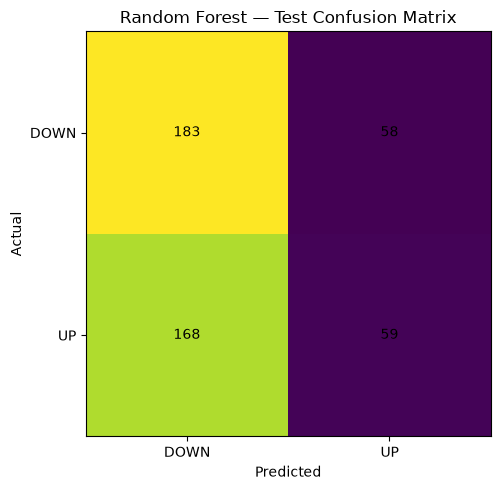


Prediction results:


,Date,Actual_Return,Predicted_Return,Actual_Direction,Predicted_Direction
0,2017-03-15,0.012037,0.000311,1,0
1,2017-03-16,0.000162,-0.000063,1,0
2,2017-03-17,-0.000566,-0.000391,0,0
3,2017-03-20,0.009177,0.000132,1,0
4,2017-03-21,-0.000240,-0.000313,0,0
5,2017-03-22,0.004000,-0.000414,1,0
6,2017-03-23,-0.002798,0.000013,0,0
7,2017-03-24,0.007338,-0.000219,1,1
8,2017-03-27,-0.006378,-0.000315,0,0
9,2017-03-28,-0.007385,-0.000099,0,0


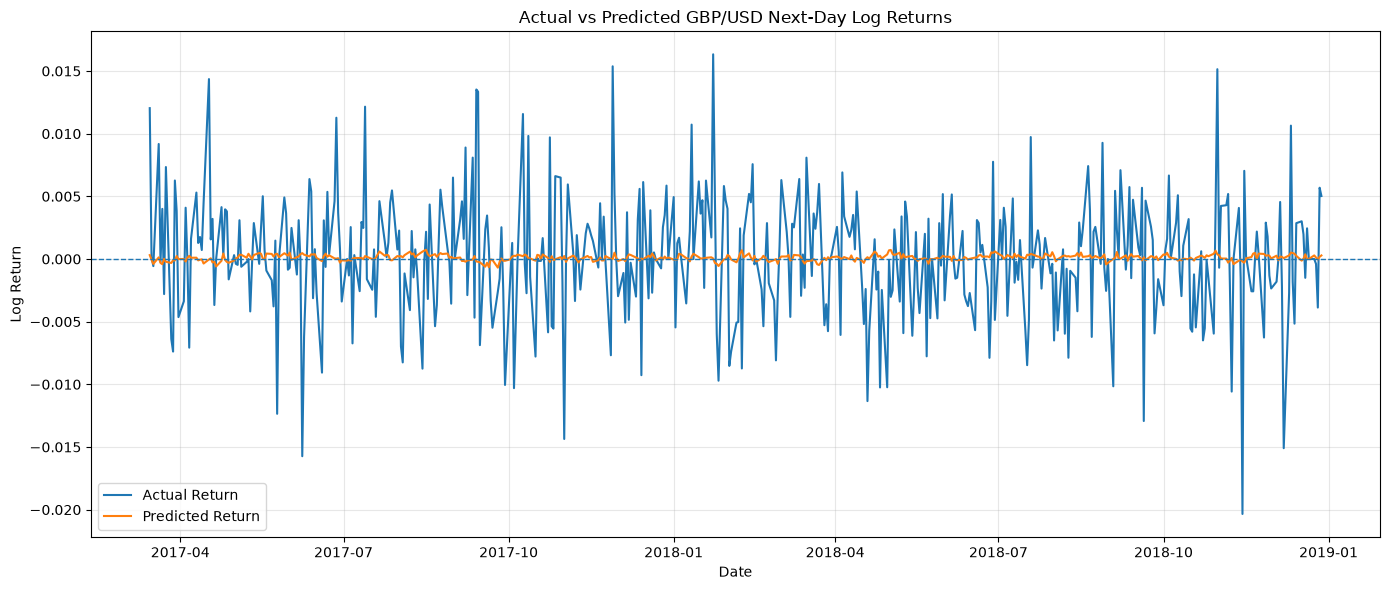


FILES SAVED SUCCESSFULLY
results/final_classification_results.csv
results/final_regression_results.csv
results/test_predictions.csv
results/figures/confusion_matrix_test.png
results/figures/actual_vs_predicted_returns.png
models/random_forest_classifier.pkl
models/lasso_regressor.pkl
models/final_scaler.pkl


In [28]:
# ============================================
# STEP 23: FINAL RESULTS, GRAPHS AND SAVING
# ============================================

import os
import joblib
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Create result directories
os.makedirs("../results/figures", exist_ok=True)
os.makedirs("../models", exist_ok=True)

# ============================================
# 1. FINAL CLASSIFICATION RESULTS
# ============================================

final_classification_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    "Validation": [
        rf_accuracy,
        rf_precision,
        rf_recall,
        rf_f1
    ],
    "Test": [
        test_accuracy,
        test_precision,
        test_recall,
        test_f1
    ]
})

print("FINAL CLASSIFICATION RESULTS")
print("=" * 60)
display(
    final_classification_results.style.format({
        "Validation": "{:.4f}",
        "Test": "{:.4f}"
    })
)

# Save
final_classification_results.to_csv(
    "../results/final_classification_results.csv",
    index=False
)


# ============================================
# 2. FINAL REGRESSION RESULTS
# ============================================

final_regression_results = pd.DataFrame({
    "Metric": [
        "MAE",
        "MSE",
        "RMSE",
        "R2"
    ],
    "Validation": [
        lasso_reg_result["MAE"],
        lasso_reg_result["MSE"],
        lasso_reg_result["RMSE"],
        lasso_reg_result["R2"]
    ],
    "Test": [
        test_mae,
        test_mse,
        test_rmse,
        test_r2
    ]
})

print("\nFINAL REGRESSION RESULTS")
print("=" * 60)
display(
    final_regression_results.style.format({
        "Validation": "{:.8f}",
        "Test": "{:.8f}"
    })
)

# Save
final_regression_results.to_csv(
    "../results/final_regression_results.csv",
    index=False
)


# ============================================
# 3. CONFUSION MATRIX
# ============================================

plt.figure(figsize=(6, 5))

plt.imshow(test_cm)

plt.title("Random Forest — Test Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks(
    [0, 1],
    ["DOWN", "UP"]
)

plt.yticks(
    [0, 1],
    ["DOWN", "UP"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            test_cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()

plt.savefig(
    "../results/figures/confusion_matrix_test.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================
# 4. ACTUAL VS PREDICTED RETURNS
# ============================================

test_dates = features_data["Date"].iloc[
    validation_end:
].reset_index(drop=True)

prediction_results = pd.DataFrame({
    "Date": test_dates,
    "Actual_Return": y_reg_test.reset_index(drop=True),
    "Predicted_Return": pd.Series(
        final_lasso_test_pred
    ).reset_index(drop=True),
    "Actual_Direction": y_class_test.reset_index(drop=True),
    "Predicted_Direction": pd.Series(
        final_rf_test_pred
    ).reset_index(drop=True)
})

print("\nPrediction results:")
display(prediction_results.head(10))

# Save predictions
prediction_results.to_csv(
    "../results/test_predictions.csv",
    index=False
)


# ============================================
# 5. ACTUAL VS PREDICTED RETURN PLOT
# ============================================

plt.figure(figsize=(14, 6))

plt.plot(
    prediction_results["Date"],
    prediction_results["Actual_Return"],
    label="Actual Return"
)

plt.plot(
    prediction_results["Date"],
    prediction_results["Predicted_Return"],
    label="Predicted Return"
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.title(
    "Actual vs Predicted GBP/USD Next-Day Log Returns"
)

plt.xlabel("Date")
plt.ylabel("Log Return")

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    "../results/figures/actual_vs_predicted_returns.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================
# 6. SAVE MODELS
# ============================================

joblib.dump(
    final_rf_classifier,
    "../models/random_forest_classifier.pkl"
)

joblib.dump(
    final_lasso,
    "../models/lasso_regressor.pkl"
)

joblib.dump(
    final_scaler,
    "../models/final_scaler.pkl"
)

print("\n============================================")
print("FILES SAVED SUCCESSFULLY")
print("============================================")

print("results/final_classification_results.csv")
print("results/final_regression_results.csv")
print("results/test_predictions.csv")
print("results/figures/confusion_matrix_test.png")
print("results/figures/actual_vs_predicted_returns.png")
print("models/random_forest_classifier.pkl")
print("models/lasso_regressor.pkl")
print("models/final_scaler.pkl")

TRADING STRATEGY BACKTEST — TEST PERIOD

Initial Investment : $10,000.00

ML Strategy
----------------------------------------
Final Value        : $9,387.11
Total Return       : -6.13%
Maximum Drawdown   : -8.86%
Sharpe Ratio       : -0.7594
Days Invested      : 117
Total Test Days    : 468

Buy-and-Hold
----------------------------------------
Final Value        : $10,385.05
Total Return       : 3.85%

Backtest Preview:


,Date,Actual_Return,Predicted_Direction,Position,Strategy_Return,Strategy_Cumulative,Buy_Hold_Cumulative
0,2017-03-15,0.012037,0,0,0.000000,1.000000,1.012037
1,2017-03-16,0.000162,0,0,0.000000,1.000000,1.012200
2,2017-03-17,-0.000566,0,0,-0.000000,1.000000,1.011627
3,2017-03-20,0.009177,0,0,0.000000,1.000000,1.020911
4,2017-03-21,-0.000240,0,0,-0.000000,1.000000,1.020666
5,2017-03-22,0.004000,0,0,0.000000,1.000000,1.024748
6,2017-03-23,-0.002798,0,0,-0.000000,1.000000,1.021881
7,2017-03-24,0.007338,1,1,0.007338,1.007338,1.029380
8,2017-03-27,-0.006378,0,0,-0.000000,1.007338,1.022814
9,2017-03-28,-0.007385,0,0,-0.000000,1.007338,1.015260


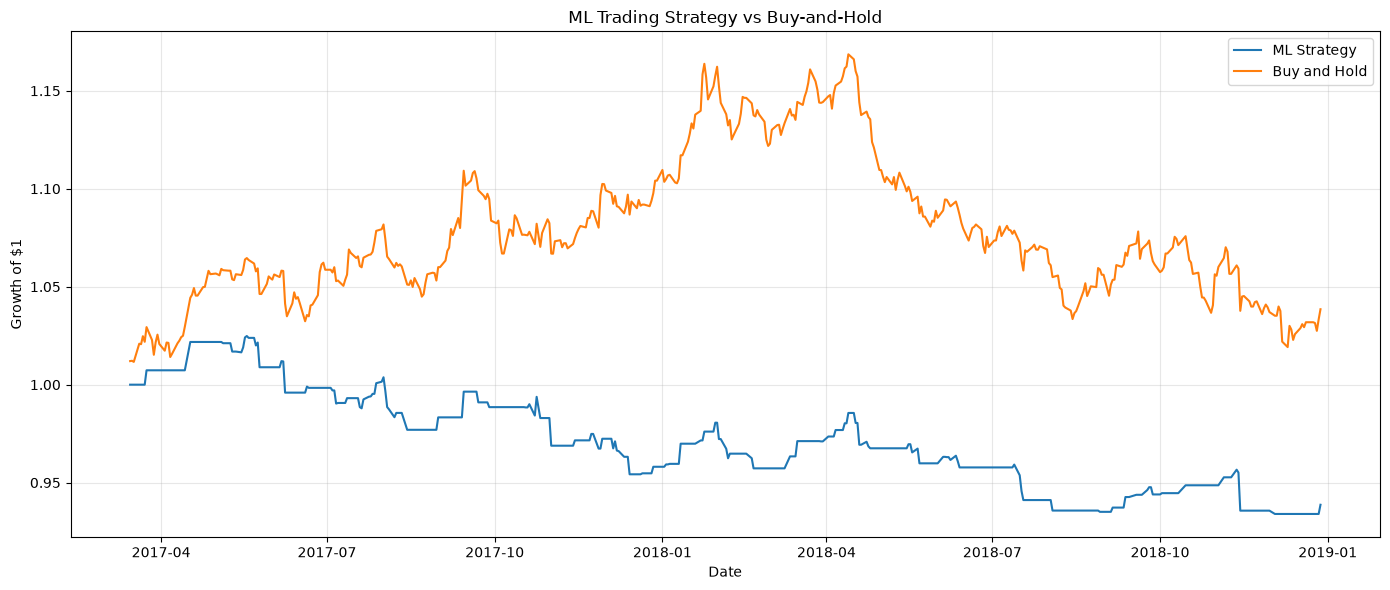


Backtest results saved:
results/backtest_results.csv
results/figures/trading_strategy_comparison.png


In [30]:
# ============================================
# STEP 24: SIMPLE TRADING STRATEGY BACKTEST
# ============================================

# Copy test prediction data
backtest_data = prediction_results.copy()

# ------------------------------------------------
# 1. CREATE TRADING POSITION
# ------------------------------------------------
# Predicted UP   = 1 -> Invest
# Predicted DOWN = 0 -> Stay out

backtest_data["Position"] = (
    backtest_data["Predicted_Direction"]
)

# ------------------------------------------------
# 2. CALCULATE DAILY STRATEGY RETURN
# ------------------------------------------------
# Position × actual next-day return

backtest_data["Strategy_Return"] = (
    backtest_data["Position"]
    * backtest_data["Actual_Return"]
)

# Buy-and-hold gets the actual return every day
backtest_data["Buy_Hold_Return"] = (
    backtest_data["Actual_Return"]
)

# ------------------------------------------------
# 3. CALCULATE CUMULATIVE RETURNS
# ------------------------------------------------

backtest_data["Strategy_Cumulative"] = (
    (1 + backtest_data["Strategy_Return"])
    .cumprod()
)

backtest_data["Buy_Hold_Cumulative"] = (
    (1 + backtest_data["Buy_Hold_Return"])
    .cumprod()
)

# ------------------------------------------------
# 4. FINAL VALUES
# ------------------------------------------------

initial_investment = 10000

strategy_final_value = (
    initial_investment
    * backtest_data["Strategy_Cumulative"].iloc[-1]
)

buy_hold_final_value = (
    initial_investment
    * backtest_data["Buy_Hold_Cumulative"].iloc[-1]
)

strategy_return_pct = (
    (strategy_final_value / initial_investment) - 1
) * 100

buy_hold_return_pct = (
    (buy_hold_final_value / initial_investment) - 1
) * 100

# ------------------------------------------------
# 5. MAXIMUM DRAWDOWN
# ------------------------------------------------

strategy_running_max = (
    backtest_data["Strategy_Cumulative"].cummax()
)

strategy_drawdown = (
    backtest_data["Strategy_Cumulative"]
    / strategy_running_max
    - 1
)

max_drawdown = strategy_drawdown.min() * 100

# ------------------------------------------------
# 6. SHARPE RATIO
# ------------------------------------------------

strategy_mean = (
    backtest_data["Strategy_Return"].mean()
)

strategy_std = (
    backtest_data["Strategy_Return"].std()
)

if strategy_std != 0:
    sharpe_ratio = (
        strategy_mean / strategy_std
    ) * np.sqrt(252)
else:
    sharpe_ratio = 0

# ------------------------------------------------
# 7. NUMBER OF TRADING DAYS
# ------------------------------------------------

trading_days = (
    backtest_data["Position"].sum()
)

total_days = len(backtest_data)

# ------------------------------------------------
# 8. DISPLAY RESULTS
# ------------------------------------------------

print("=" * 65)
print("TRADING STRATEGY BACKTEST — TEST PERIOD")
print("=" * 65)

print(f"\nInitial Investment : ${initial_investment:,.2f}")

print("\nML Strategy")
print("-" * 40)
print(f"Final Value        : ${strategy_final_value:,.2f}")
print(f"Total Return       : {strategy_return_pct:.2f}%")
print(f"Maximum Drawdown   : {max_drawdown:.2f}%")
print(f"Sharpe Ratio       : {sharpe_ratio:.4f}")
print(f"Days Invested      : {trading_days}")
print(f"Total Test Days    : {total_days}")

print("\nBuy-and-Hold")
print("-" * 40)
print(f"Final Value        : ${buy_hold_final_value:,.2f}")
print(f"Total Return       : {buy_hold_return_pct:.2f}%")

# ------------------------------------------------
# 9. SHOW FIRST FEW BACKTEST OBSERVATIONS
# ------------------------------------------------

print("\nBacktest Preview:")
display(
    backtest_data[
        [
            "Date",
            "Actual_Return",
            "Predicted_Direction",
            "Position",
            "Strategy_Return",
            "Strategy_Cumulative",
            "Buy_Hold_Cumulative"
        ]
    ].head(10)
)

# ------------------------------------------------
# 10. PLOT PERFORMANCE
# ------------------------------------------------

plt.figure(figsize=(14, 6))

plt.plot(
    backtest_data["Date"],
    backtest_data["Strategy_Cumulative"],
    label="ML Strategy"
)

plt.plot(
    backtest_data["Date"],
    backtest_data["Buy_Hold_Cumulative"],
    label="Buy and Hold"
)

plt.title(
    "ML Trading Strategy vs Buy-and-Hold"
)

plt.xlabel("Date")
plt.ylabel("Growth of $1")

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    "../results/figures/trading_strategy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------
# 11. SAVE BACKTEST RESULTS
# ------------------------------------------------

backtest_data.to_csv(
    "../results/backtest_results.csv",
    index=False
)

print("\nBacktest results saved:")
print("results/backtest_results.csv")
print("results/figures/trading_strategy_comparison.png")

In [31]:
# ============================================
# STEP 25: FINAL PROJECT SUMMARY
# ============================================

print("=" * 70)
print("FOREIGN CURRENCY EXCHANGE RATE FORECAST")
print("FINAL PROJECT SUMMARY")
print("=" * 70)

print("\nDATASET")
print("-" * 70)
print(f"Observations used for modeling : {len(features_data)}")
print(f"Features                        : {X_train.shape[1]}")
print("Currency pairs                  : GBP/USD, USD/EUR, USD/JPY")
print("Period                          : 2001–2018")
print("Split                           : 80% Train / 10% Validation / 10% Test")

print("\nCLASSIFICATION")
print("-" * 70)
print("Best model: Random Forest")

print(f"Validation Accuracy : {rf_accuracy:.4f}")
print(f"Validation F1       : {rf_f1:.4f}")
print(f"Test Accuracy       : {test_accuracy:.4f}")
print(f"Test F1             : {test_f1:.4f}")

print("\nREGRESSION")
print("-" * 70)
print("Best model: Lasso")

print(f"Validation RMSE : {lasso_reg_result['RMSE']:.8f}")
print(f"Validation R²   : {lasso_reg_result['R2']:.4f}")
print(f"Test RMSE       : {test_rmse:.8f}")
print(f"Test R²         : {test_r2:.4f}")

print("\nXGBOOST EXTENSION")
print("-" * 70)
print("XGBoost was evaluated as an additional model.")
print(
    f"Validation RMSE : "
    f"{xgb_reg_result['RMSE']:.8f}"
)
print(
    f"Validation R²   : "
    f"{xgb_reg_result['R2']:.4f}"
)

print("\nTRADING BACKTEST")
print("-" * 70)
print(f"ML Strategy Return : {strategy_return_pct:.2f}%")
print(f"Buy & Hold Return  : {buy_hold_return_pct:.2f}%")
print(f"Maximum Drawdown   : {max_drawdown:.2f}%")
print(f"Sharpe Ratio       : {sharpe_ratio:.4f}")

print("\nCONCLUSION")
print("-" * 70)

print(
    "The Random Forest classifier achieved approximately "
    f"{test_accuracy:.2%} test accuracy."
)

print(
    "The Lasso regression model achieved a test RMSE of "
    f"{test_rmse:.8f}."
)

print(
    "The XGBoost extension was evaluated but did not outperform "
    "the best reference regression model on the validation set."
)

print(
    "The simple ML trading strategy returned "
    f"{strategy_return_pct:.2f}% compared with "
    f"{buy_hold_return_pct:.2f}% for buy-and-hold."
)

print(
    "\nOverall, the experiments show that short-term FX return "
    "forecasting remains challenging and that predictive accuracy "
    "does not necessarily translate into profitable trading performance."
)

print("\n" + "=" * 70)
print("PROJECT EXPERIMENTS COMPLETE")
print("=" * 70)

FOREIGN CURRENCY EXCHANGE RATE FORECAST
FINAL PROJECT SUMMARY

DATASET
----------------------------------------------------------------------
Observations used for modeling : 4673
Features                        : 36
Currency pairs                  : GBP/USD, USD/EUR, USD/JPY
Period                          : 2001–2018
Split                           : 80% Train / 10% Validation / 10% Test

CLASSIFICATION
----------------------------------------------------------------------
Best model: Random Forest
Validation Accuracy : 0.5161
Validation F1       : 0.5350
Test Accuracy       : 0.5171
Test F1             : 0.3430

REGRESSION
----------------------------------------------------------------------
Best model: Lasso
Validation RMSE : 0.00740834
Validation R²   : -0.0059
Test RMSE       : 0.00487818
Test R²         : -0.0074

XGBOOST EXTENSION
----------------------------------------------------------------------
XGBoost was evaluated as an additional model.
Validation RMSE : 0.00786628
Va

In [32]:
# ============================================
# SAVE RAW DATA FOR PROJECT SUBMISSION
# ============================================

import os

os.makedirs("../data/raw", exist_ok=True)

gbp.to_csv(
    "../data/raw/GBP_USD.csv",
    index=False
)

eur.to_csv(
    "../data/raw/USD_EUR.csv",
    index=False
)

jpy.to_csv(
    "../data/raw/USD_JPY.csv",
    index=False
)

print("RAW DATA SAVED SUCCESSFULLY")
print("--------------------------------")
print("data/raw/GBP_USD.csv")
print("data/raw/USD_EUR.csv")
print("data/raw/USD_JPY.csv")

RAW DATA SAVED SUCCESSFULLY
--------------------------------
data/raw/GBP_USD.csv
data/raw/USD_EUR.csv
data/raw/USD_JPY.csv
